<a href="https://colab.research.google.com/github/oooinr4018-web/-1/blob/main/ESAA_1120_%EA%B3%BC%EC%A0%9C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 7.6. 게이트 순환 신경망 (GRU)

GRU: 게이트 메커니즘이 적용된 RNN 프레임워크의 한 종류, LSTM보다 간단한 구조


# 7.6.1. GRU 구조

GRU: LSTM에서 사용하는 망각 게이트, 입력 게이트를 하나로 합친 것 + 별도의 업데이트 게이트로 구성

- 출력 게이트 존재 X -> 전체 상태 벡터가 매 단계마다 출력

게이트 컨트롤러: 망각 게이트, 입력 게이트 모두 제어

- 1 출력 - 망각 게이트 열림, 입력 게이트 닫힘

- 0 출력 - 망각 게이트 닫힘, 입력 게이트 열림

- 이전 기억이 저장될 때마다 단계별 입력 삭제

- 이전 상태의 어느 부분이 출력될지 제어하는 새로운 게이트 컨트롤러 별도로 존재

망각 게이트

- 목적: 과거 정보를 적당히 초기화

- 시그모이드 함수를 출력으로, (0,1) 값을 이전 은닉층에 곱하기

(이전 시점의 은닉층 값 x 현시점의 정보에 대한 가중치)

업데이트 게이트: 과거, 현재 정보의 최신화 비율 결정 역할

: (1-zt) * (직전 시점의 은닉층 정보)

(시그모이드로 출력된 결과(zt)로 현시점의 정보량 결정)

후보군: 현시점의 정보에 대한 후보군 계산

- 과거 은닉층의 정보를 그대로 이용 X, 망각 게이트의 결과를 이용하여 후보군 계산

은닉층 계산: 업데이트 게이트 결과, 후보군 결과 결합하여 현시점의 은닉층 계산

: 시그모이드 함수의 결과 -> 현시점의 결과에 대한 정보량 결정

: 1-(시그모이드 함수의 결과) -> 과거의 정보량 결정







# 7.6.2. GRU 셀 구현

파이토치로 GRU 셀 구현

데이터셋 코드: LSTN 셀과 동일



In [35]:
# 코드 7-52. 라이브러리 호출
import torch
import torch.nn as nn
import torchvision.transforms as transforms
import torchvision.datasets as dataset
from torch.autograd import Variable
from torch.nn import Parameter
from torch import Tensor
import torch.nn.functional as F
from torch.utils.data import DataLoader
import math

device=torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
cuda=True if torch.cuda.is_available() else False

Tensor=torch.cuda.FolatTensor if cuda else torch.FloatTensor

torch.manual_seed(125)
if torch.cuda.is_available():
  torch.cuda.manual_seed_all(125)

In [36]:
# 코드 7-53. 데이터 전처리
mnist_transform=transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (1.0,))
    ])

In [37]:
# 코드 7-54. 데이터셋 내려받기 및 전처리 적용
from torchvision.datasets import MNIST
download_root='../chap07/MNIST_DATASET'

train_dataset=MNIST(download_root, transform=mnist_transform, train=True,
                    download=True)
valid_dataset=MNIST(download_root, transform=mnist_transform, train=False,
                    download=True)
test_dataset=MNIST(download_root, transform=mnist_transform, train=False,
                   download=True)



- GPU 셀에서도 MNIST 데이터셋 사용
- MNIST 데이터셋 다운로드 -> 전처리

In [38]:
# 코드 7-55. 데이터셋 메모리로 가져오기
batch_size=64
train_loader=DataLoader(dataset=train_dataset,
                        batch_size=batch_size,
                        shuffle=True)
valid_loader=DataLoader(dataset=test_dataset,
                        batch_size=batch_size,
                        shuffle=True)
test_loader=DataLoader(dataset=test_dataset,
                       batch_size=batch_size,
                       shuffle=True)

- 데이터로더 -> 전처리된 데이터셋을 메모리로 불러오기

- 메모리로 불러오는 시점 = train_loader, valid_loader, test_loader가 호출되는 시점

In [39]:
# 코드 7-56. 변수 값 설정
batch_size=100
n_iters=6000
num_epochs=n_iters/(len(train_dataset)/batch_size)
num_epochs=int(num_epochs)

- 필요한 변수에 대한 값 설정

In [56]:
# 코드 7-57. GRU 셀 네트워크
class GRUCell(nn.Module):
  def __init__(self, input_size, hidden_size, bias=True):
    super(GRUCell, self).__init__()
    self.input_size=input_size
    self.hidden_size=hidden_size
    self.bias=bias
    self.x2h=nn.Linear(input_size, 3*hidden_size, bias=bias)
    self.h2h=nn.Linear(hidden_size, 3*hidden_size, bias=bias)
    self.reset_parameters()

  def reset_parameters(self):
    std=1.0 / math.sqrt(self.hidden_size)
    for w in self.parameters():
      w.data.uniform_(-std,std)

  def forward(self, x, hidden):
    x=x.view(-1, x.size(1))

    gate_x=self.x2h(x) # LSTM 셀에서는 gates를 x2h+h2h로 정의 #GRU 셀에서 개별적인 상태 유지
    gate_h=self.h2h(hidden)
    gate_x=gate_x.squeeze()
    gate_h=gate_h.squeeze()

    i_r, i_i, i_n=gate_x.chunk(3, 1) # 총 세 개의 게이트(망각, 입력, 새로운 게이트)를 위해 세 개로 쪼개기
    h_r, h_i, h_n=gate_h.chunk(3,1)

    resetgate=F.sigmoid(i_r+h_r)
    inputgate=F.sigmoid(i_i+h_i)
    newgate=F.tanh(i_n+(resetgate*h_n)) # '새로운 게이트'는 탄젠트 활성화 함수가 적용된 게이트

    hy=newgate+inputgate*(hidden-newgate)
    return hy

- GRU 셀: 세 개의 게이트 사용 -> 3 곱하기 <-> LSTM 셀: 4 곱하기

(망각, 입력 게이트 + 새로운 게이트(탄젠트 활성화 함수 적용 부분))



In [57]:
# 코드 7-58. 전반적인 네트워크 구조
class GRUModel(nn.Module):
  def __init__(self, input_dim, hidden_dim, layer_dim, output_dim, bias=True):
    super(GRUModel, self).__init__()
    self.hidden_dim=hidden_dim
    self.layer_dim=layer_dim

    self.gru_cell=GRUCell(input_dim, hidden_dim, layer_dim) # 앞에서 정의한 GRUCell 함수 불러오기
    self.fc=nn.Linear(hidden_dim, output_dim)

  def forward(self, x):
    if torch.cuda.is_available():
      h0=Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim).cuda())
    else:
      h0=Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim))

    outs=[]
    hn=h0[0,:,:] # LSTM 셀에서는 셀 상태에 대해서 정의 # GRU 셀에서는 셀 사용 X

    for seq in range(x.size(1)):
      hn=self.gru_cell(x[:,seq,:], hn)
      outs.append(hn)

    out=outs[-1].squeeze()
    out=self.fc(out)
    return out



In [58]:
# 코드 7-59. 옵티마이저와 손실 함수 설정
# 모델에 적용될 변수 값 및 옵티마이저, 손실 함수 설정
input_dim=28
hidden_dim=128
layer_dim=1
output_dim=10

model=GRUModel(input_dim, hidden_dim, layer_dim, output_dim)

if torch.cuda.is_available():
  model.cuda()

criterion=nn.CrossEntropyLoss()
learning_rate=0.1
optimizer=torch.optim.SGD(model.parameters(), lr=learning_rate)

In [59]:
# 코드 7-60. 모델 학습 및 성능 검증
seq_dim=28
loss_list=[]
iter=0
for epoch in range(num_epochs):
  for i, (images, labels) in enumerate(train_loader):
    if torch.cuda.is_available():
      images=Variable(images.view(-1, seq_dim, input_dim).cuda())
      labels=Variable(labels.cuda())

    else:
      images=Variable(images.view(-1, seq_dim, input_dim))
      labels=Variable(labels)

    optimizer.zero_grad()
    outputs=model(images)
    loss=criterion(outputs, labels)

    if torch.cuda.is_available():
      loss.cuda()

    loss.backward()
    optimizer.step()

    loss_list.append(loss.item())
    iter+=1

    if iter%500==0:
      correct=0
      total=0
      for images, labels in valid_loader:
        if torch.cuda.is_available():
          images=Variable(images.view(-1, seq_dim, input_dim).cuda())
        else:
          images=Variable(images.view(-1, seq_dim, input_dim))

        outputs=model(images)
        _, predicted=torch.max(outputs.data, 1)
        total+=labels.size(0)

        if torch.cuda.is_available():
          correct+=(predicted.cpu()==labels.cpu()).sum()

      accuracy=100*correct/total
      print('Iteration: {}. Loss: {}. Accuracy: {}'.format(iter, loss.item(),
                                                               accuracy))


Iteration: 500. Loss: 1.5964155197143555. Accuracy: 0.0
Iteration: 1000. Loss: 0.6850054860115051. Accuracy: 0.0
Iteration: 1500. Loss: 0.4145250916481018. Accuracy: 0.0
Iteration: 2000. Loss: 0.18953914940357208. Accuracy: 0.0
Iteration: 2500. Loss: 0.22502398490905762. Accuracy: 0.0
Iteration: 3000. Loss: 0.02401692047715187. Accuracy: 0.0
Iteration: 3500. Loss: 0.08355513960123062. Accuracy: 0.0
Iteration: 4000. Loss: 0.20342877507209778. Accuracy: 0.0
Iteration: 4500. Loss: 0.09804931282997131. Accuracy: 0.0
Iteration: 5000. Loss: 0.062879279255867. Accuracy: 0.0
Iteration: 5500. Loss: 0.05097296088933945. Accuracy: 0.0
Iteration: 6000. Loss: 0.014894789084792137. Accuracy: 0.0
Iteration: 6500. Loss: 0.06923180818557739. Accuracy: 0.0
Iteration: 7000. Loss: 0.11086671054363251. Accuracy: 0.0
Iteration: 7500. Loss: 0.13492944836616516. Accuracy: 0.0
Iteration: 8000. Loss: 0.061968643218278885. Accuracy: 0.0
Iteration: 8500. Loss: 0.012577316723763943. Accuracy: 0.0
Iteration: 9000. 

모델 학습 결과

- LSTM 셀 실행했을 때의 정확도와 유사

(LSTM 셀, GRU 셀 -> 정확도 비슷 -> 시계열 처리 관련 모델 (RNN, LSTM, GRU) 중 어떤 것이 좋은지 알 수 X -> 주어진 데이터셋을 다양한 모델에 적용)



In [60]:
# 코드 7-61. 테스트 데이터셋을 이용한 모델 예측
# 예측에 대한 성능 확인

def evaluate(model, val_iter):
  corrects, total, total_loss=0,0,0
  model.eval()
  for images, labels in val_iter:
    if torch.cuda.is_available():
      images=Variable(images.view(-1, seq_dim, input_dim).cuda())
    else:
      images=Variable(images.view(-1, seq_dim, input_dim)).to(device)

    logit=model(images).to(device)
    loss=F.cross_entropy(logit, labels, reduction="sum")
    _, predicted=torch.max(logit.data, 1)
    total+=labels.size(0)
    total_loss+=loss.item()
    corrects+=(predicted==labels).sum()

  avg_loss=total_loss/len(val_iter.dataset)
  avg_accuracy=corrects/total
  return avg_loss, avg_accuracy

In [61]:
# 코드 7-62. 모델 예측 결과
test_loss, test_acc=evaluate(model, test_loader)
print("Test Loss: %5.2f | Test Accuracy: %5.2f" % (test_loss, test_acc))

Test Loss:  0.07 | Test Accuracy:  0.98


테스트 데이터셋을 이용했을 때의 모델의 예측력

- 예측력(정확도); 98% (상당히 높은 결과) (=LSTM 셀 사용했을 때의 성능)

- MNIST 데이터셋에 대해 높은 성능, 또 다른 데이터셋 적용 시 정확도가 낮을 수도 있음.

-> 주어진 데이터셋에 대한 다양한 모델 적용하여 최적의 하이퍼파라미터 찾는 것이 중요함.


# 7.6.3. GRU 계층 구현

GRU 계층에 대한 파이토치를 이용한 예제

LSTM 계층에서 사용했던 데이터셋, 코드와 유사

모델의 네트워크 위주로 학습 진행 예정



In [62]:
# 코드 7-63. 라이브러리 호출

import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, dataloader
from torch.autograd import Variable
from tqdm import tqdm_notebook
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
device=torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')


In [65]:
!pip install -q yfinance

In [66]:
# 쿄드 7-64. 데이터셋 불러오기

import yfinance as yf
import pandas as pd

data = yf.download(
    "SBUX",
    start="2015-01-01",
    end="2020-01-01",
    auto_adjust=False,
    multi_level_index=False
)

if data.empty:
    raise ValueError("주가 데이터를 다운로드하지 못했습니다.")

data.to_csv("/content/SBUX.csv")

print(data.dtypes)
print(data.head())

[*********************100%***********************]  1 of 1 completed

Adj Close    float64
Close        float64
High         float64
Low          float64
Open         float64
Volume         int64
dtype: object
            Adj Close      Close       High        Low       Open    Volume
Date                                                                       
2015-01-02  31.888321  40.720001  41.490002  40.445000  41.064999   6886000
2015-01-05  31.277493  39.939999  40.334999  39.744999  40.070000  11623800
2015-01-06  31.022980  39.615002  40.195000  39.279999  40.169998   7664400
2015-01-07  31.786516  40.590000  40.615002  39.700001  39.875000   9732600
2015-01-08  32.299450  41.244999  41.650002  41.009998  41.165001  13170600


- 스타벅스 주가 데이터셋의 각 칼럼에 대한 데이터 형식 살펴보기

In [70]:
# 코드 7-65. 인덱스 설정 및 데이터 타입 변경
data.index = pd.to_datetime(data.index)
data['Volume'] = data['Volume'].astype(float)

- 'Date' 칼럼을 인덱스로 지정

- 'Volume' 칼럼의 데이터 형식을 실수(float)로 변경

(대문자, 소문자를 구분하여 'Date'를 'date'로 사용 시 오류 발생)

In [71]:
# 코드 7-66. 훈련과 레이블 데이터셋 분리
X=data.iloc[:, :-1]
y=data.iloc[:, 5:6]
print(X)
print(y)

            Adj Close      Close       High        Low       Open
Date                                                             
2015-01-02  31.888321  40.720001  41.490002  40.445000  41.064999
2015-01-05  31.277493  39.939999  40.334999  39.744999  40.070000
2015-01-06  31.022980  39.615002  40.195000  39.279999  40.169998
2015-01-07  31.786516  40.590000  40.615002  39.700001  39.875000
2015-01-08  32.299450  41.244999  41.650002  41.009998  41.165001
...               ...        ...        ...        ...        ...
2019-12-24  75.665573  88.519997  88.599998  88.000000  88.199997
2019-12-26  75.289490  88.080002  88.760002  87.790001  88.730003
2019-12-27  75.332222  88.129997  88.459999  87.690002  88.110001
2019-12-30  74.742409  87.440002  88.199997  87.059998  88.010002
2019-12-31  75.152718  87.919998  87.989998  87.309998  87.440002

[1258 rows x 5 columns]
                Volume
Date                  
2015-01-02   6886000.0
2015-01-05  11623800.0
2015-01-06   7664400.0
20

훈련(x), 레이블(y)에 대한 데이터 출력 결과

In [72]:
# 코드 7-67. 훈련과 테스트 데이터셋 정규화
ms=MinMaxScaler()
ss=StandardScaler()

X_ss=ss.fit_transform(X)
y_ms=ms.fit_transform(y)

X_train=X_ss[:200, :]
X_test=X_ss[200:, :]
y_train=y_ms[:200, :]
y_test=y_ms[200:, :]

print("Training Shape", X_train.shape, y_train.shape)
print("Testing Shape", X_test.shape, y_test.shape)

Training Shape (200, 5) (200, 1)
Testing Shape (1058, 5) (1058, 1)


훈련, 테스트 데이터셋의 형태에 대한 출력 결과

In [73]:
# 코드 7-68. 데이터셋 형태 변경
X_train_tensors=Variable(torch.Tensor(X_train))
X_test_tensors=Variable(torch.Tensor(X_test))

y_train_tensors=Variable(torch.Tensor(y_train))
y_test_tensors=Variable(torch.Tensor(y_test))

X_train_tensors_f=torch.reshape(X_train_tensors, (X_train_tensors.shape[0],
                                                  1, X_train_tensors.shape[1]))
X_test_tensors_f=torch.reshape(X_test_tensors, (X_test_tensors.shape[0],
                                                1, X_test_tensors.shape[1]))

print("Training Shape", X_train_tensors_f.shape, y_train_tensors.shape)
print("Testing Shape", X_test_tensors_f.shape, y_test_tensors.shape)

Training Shape torch.Size([200, 1, 5]) torch.Size([200, 1])
Testing Shape torch.Size([1058, 1, 5]) torch.Size([1058, 1])


변경된 훈련, 테스트 데이터셋의 형태 출력 결과

In [74]:
# 코드 7-69. GRU 모델의 네트워크
class GRU(nn.Module):
  def __init__(self, num_classes, input_size, hidden_size, num_layers, seq_length):
    super(GRU, self).__init__()
    self.num_classes=num_classes
    self.num_layers=num_layers
    self.input_size=input_size
    self.hidden_size=hidden_size
    self.seq_length=seq_length

    self.gru=nn.GRU(input_size=input_size, hidden_size=hidden_size,
                    num_layers=num_layers, batch_first=True)
    self.fc_1=nn.Linear(hidden_size, 128)
    self.fc=nn.Linear(128, num_classes)
    self.relu=nn.ReLU()

  def forward(self, x):
    h_0=Variable(torch.zeros(self.num_layers, x.size(0), self.hidden_size)) # 은닉 상태에 대해 0으로 초기화하는 부분 # LSTM 계층은 셀 상태가 있었지만 GRU는 셀 상태 정의 X
    output, (hn)=self.gru(x, (h_0))
    hn=hn.view(-1, self.hidden_size)
    out=self.relu(hn)
    out=self.fc_1(out)
    out=self.relu(out)
    out=self.fc(out)
    return out


GRU 모델의 네트워크 살펴보기

-> LSTM 계층과의 차이점 위주로 학습

In [75]:
# 코드 7-70. 옵티마이저와 손실 함수 지정
num_epochs=1000
learning_rate=0.0001

input_size=5
hidden_size=2
num_layers=1 # GRU 계층의 개수

num_classes=1
model=GRU(num_classes, input_size, hidden_size, num_layers, X_train_tensors_f.shape[1])

griterion=torch.nn.MSELoss()
optimizer=torch.optim.Adam(model.parameters(), lr=learning_rate)

모델을 훈련시키기 위한 변수 값, 옵티마이저, 손실 함수 지정

In [76]:
# 코드 7-71. 모델 학습
for epoch in range(num_epochs):
  outputs=model.forward(X_train_tensors_f)
  optimizer.zero_grad()
  loss=criterion(outputs, y_train_tensors)
  loss.backward()

  optimizer.step()
  if epoch%100==0:
    print("Epoch: %d, loss: %1.5f" % (epoch, loss.item()))

Epoch: 0, loss: -0.00000
Epoch: 100, loss: -0.00000
Epoch: 200, loss: -0.00000
Epoch: 300, loss: -0.00000
Epoch: 400, loss: -0.00000
Epoch: 500, loss: -0.00000
Epoch: 600, loss: -0.00000
Epoch: 700, loss: -0.00000
Epoch: 800, loss: -0.00000
Epoch: 900, loss: -0.00000


모델 학습 결과

In [77]:
# 코드 7-72. 그래프 출력을 위한 전처리
df_x_ss=ss.transform(data.iloc[:, :-1])
df_y_ms=ms.transform(data.iloc[:, -1:])

df_x_ss=Variable(torch.Tensor(df_x_ss))
df_y_ms=Variable(torch.Tensor(df_y_ms))
df_x_ss=torch.reshape(df_x_ss, (df_x_ss.shape[0], 1, df_x_ss.shape[1]))

데이터를 그래프로 출력하기 위한 준비

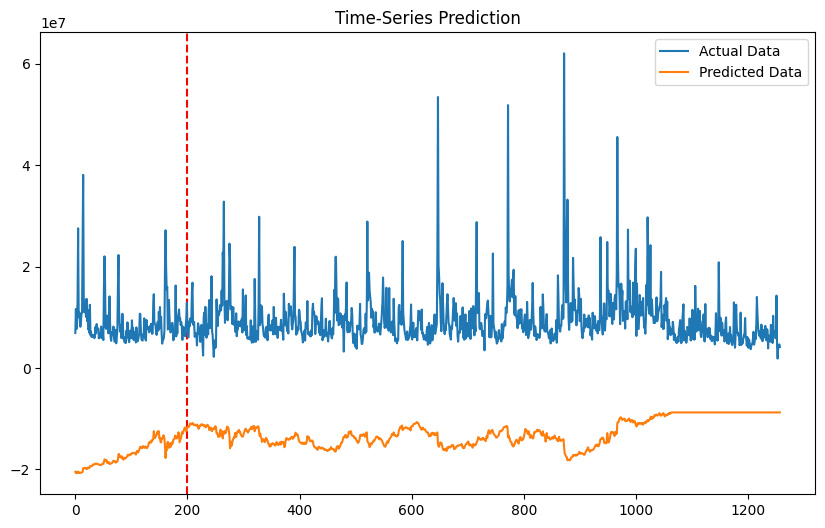

In [78]:
# 코드 7-73. 모델 예측 결과 출력
train_predict=model(df_x_ss)
predicted=train_predict.data.numpy()
label_y=df_y_ms.data.numpy()

predicted=ms.inverse_transform(predicted)
label_y=ms.inverse_transform(label_y)
plt.figure(figsize=(10,6))
plt.axvline(x=200, c='r', linestyle='--')

plt.plot(label_y, label='Actual Data')
plt.plot(predicted, label='Predicted Data')
plt.title('Time-Series Prediction')
plt.legend()
plt.show()

모델의 예측 결과, 레이블 비교하여 그래프로 출력한 결과

- GRU 계층을 사용했을 때가 LSTM 계층을 사용햇을 때보다 예측력이 더 좋아보임.

(수치상 모델 예측 정확도는 유사 / 훈련 데이터를 섞어서(shuffle) 가져오도록 했기 때문에 결과가 다를 수 있음.)

# 7.7. 양방향 RNN

RNN: 이전 시점의 데이터들을 참고해서 정답 예측

실제 문제에서는 과거 시점, 미래 시점의 데이터에서 힌트를 얻음.

-> 양방향 RNN: 이전 시점의 데이터, 이후 시점의 데이터 함께 활용하여 출력 값 예측

# 7.7.1. 양방향 RNN 구조
양방향 RNN: 하나의 출력 값을 예측하는 데 메모리 셀 두 개 사용

첫 번째 메모리 셀: 이전 시점의 은닉 상태를 전달받아 현재의 은닉 상태 계산

두 번째 메모리 셀: 다음 시점의 은닉 상태를 전달받아 현재의 은닉 상태 계산

-> 두 값은 모두 출력층에서 출력 값 예측 시 사용

-> RNN, LSTM, GRU에도 적용됨

# 7.7.2. 양방향 LSTM 구현

스타벅스 주가 예측 데이터셋을 사용한 예제 활용

LSTM 계층에서 사용했던 코드와 동일

In [83]:
# 코드 7-74. 모델을 생성하고 학습

import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.autograd import Variable
from tqdm import tqdm_notebook
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
device=torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

data = pd.read_csv('/content/SBUX.csv')
print(data.dtypes)

data['Date']=pd.to_datetime(data['Date'])
data.set_index('Date', inplace=True)
data['Volume']=data['Volume'].astype(float)

X=data.iloc[:, :-1]
y=data.iloc[:, 5:6]

ms=MinMaxScaler()
ss=StandardScaler()

X_ss=ss.fit_transform(X)
y_ms=ms.fit_transform(y)

X_train=X_ss[:200, :]
X_test=X_ss[200:, :]
y_train=y_ms[:200, :]
y_test=y_ms[200:, :]

X_train_tensors=Variable(torch.Tensor(X_train))
X_test_tensors=Variable(torch.Tensor(y_test))

X_train_tensors_f=torch.reshape(X_train_tensors, (X_train_tensors.shape[0],
                                                  1, X_train_tensors.shape[1]))
X_test_tensors_f=torch.reshape(X_test_tensors, (X_test_tensors.shape[0],
                                                1, X_test_tensors.shape[1]))



Date          object
Adj Close    float64
Close        float64
High         float64
Low          float64
Open         float64
Volume         int64
dtype: object


In [86]:
# 코드 7-75. 모델의 네트워크

class biLSTM(nn.Module):
  def __init__(self, num_classes, input_size, hidden_size, num_layers, seq_length):
    super(biLSTM, self).__init__()
    self.num_classes=num_classes
    self.num_layers=num_layers
    self.input_size=input_size
    self.hidden_size=hidden_size
    self.seq_length=seq_length

    self.lstm=nn.LSTM(input_size=input_size, hidden_size=hidden_size,
                      num_layers=num_layers, bidirectional=True, batch_first=True)
    self.fc=nn.Linear(hidden_size*2, num_classes)
    self.relu=nn.ReLU()

  def forward(self,x):
    h_0=Variable(torch.zeros(self.num_layers*2, x.size(0), self.hidden_size))
    c_0=Variable(torch.zeros(self.num_layers*2, x.size(0), self.hidden_size))
    out, _=self.lstm(x, (h_0, c_0))
    out=self.fc(out[:, -1, :])
    out=self.relu(out)
    return out

- nn.LSTM에 bidirectional=True 옵션 사용: 양방향 LSTM

(양방향 RNN, 양방향 GPU 모두 해당)

- 한 번 학습 시, 두 개의 계층 필요

(은닉 상태, 셀 상태, 마지막 출력층에 2 곱하기)

In [87]:
# 코드 7-76. 모델 학습

num_epochs=1000
learning_rate=0.0001

input_size=5
hidden_size=2
num_layers=1
num_classes=1
model=biLSTM(num_classes, input_size, hidden_size, num_layers,
             X_train_tensors_f.shape[1])

criterion=torch.nn.MSELoss()
optimizer=torch.optim.Adam(model.parameters(), lr=learning_rate)

for epoch in range(num_epochs):
  outputs=model.forward(X_train_tensors_f)
  optimizer.zero_grad()

  loss=criterion(outputs, y_train_tensors)
  loss.backward()
  optimizer.step()
  if epoch%100==0:
    print("Epoch: %d, loss: %1.5f" % (epoch, loss.item()))

Epoch: 0, loss: 0.01065
Epoch: 100, loss: 0.00668
Epoch: 200, loss: 0.00517
Epoch: 300, loss: 0.00478
Epoch: 400, loss: 0.00469
Epoch: 500, loss: 0.00465
Epoch: 600, loss: 0.00463
Epoch: 700, loss: 0.00461
Epoch: 800, loss: 0.00459
Epoch: 900, loss: 0.00459


양방향 LSTM 모델 학습 결과

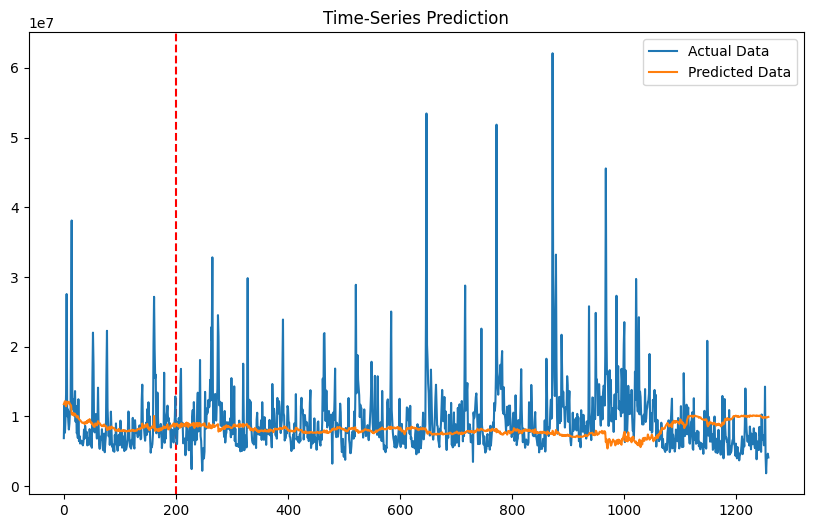

In [88]:
# 코드 7-77. 모델 평가

df_x_ss=ss.transform(data.iloc[:, :-1])
df_y_ms=ms.transform(data.iloc[:, -1:])

df_x_ss=Variable(torch.Tensor(df_x_ss))
df_y_ms=Variable(torch.Tensor(df_y_ms))
df_x_ss=torch.reshape(df_x_ss, (df_x_ss.shape[0], 1, df_x_ss.shape[1]))

train_predict=model(df_x_ss)
predicted=train_predict.data.numpy()
label_y=df_y_ms.data.numpy()

predicted=ms.inverse_transform(predicted)
label_y=ms.inverse_transform(label_y)
plt.figure(figsize=(10,6))
plt.axvline(x=200, c='r', linestyle='--')

plt.plot(label_y, label='Actual Data')
plt.plot(predicted, label='Predicted Data')
plt.title('Time-Series Prediction')
plt.legend()
plt.show()

- 학습이 진행될수록 오차가 줄어들어 훈련이 잘된 것 같지만 어느 정도 잘 된 것인지 알기 어려움. -> 모델의 예측력 알아보기

- LSTM과 동일한 코드

- 데이터가 랜덤으로 섞이기 때문에 실행할 때마다 결과가 다를 수 있음.

- 파란색: 실제 레이블에 대한 결과, 주황색: 모델이 예측한 결과

-> 파란색, 주황색 유사 -> 예측력 좋음.

- LSTM과 비교 시 예측 결과는 좋다고 예측 가능

- 다른 유형의 데이터 사용 시 결과 다를 수 있음.

- 시계열 데이터들은 일반적인 숫자의 나열보다 한글, 영문, 사람의 언어(자연어)로 구현된 데이터가 대부분 -> 데이터에 대한 처리가 중요